# RQ2 v2 — What does progressive redundancy reduction actually do to functional prediction?

## Scientific question

**How does progressively removing redundant sequence support alter functional prediction, and how much of the resulting performance change can be explained by the amount versus the structure of the remaining training evidence?**

Redundancy threshold:

\[
R \in \{90,70,50,30\}
\]

with lower `R` corresponding to more aggressive redundancy reduction.

This notebook analyzes the complete supervised benchmark while **holding `S` fixed whenever the effect of `R` is estimated**.

### Main objectives

1. reconstruct the complete `R90 → R70 → R50 → R30` response;
2. quantify all six possible `R` contrasts at fixed `S`;
3. identify monotonic, threshold-like, flat, and non-monotonic regimes;
4. determine which tasks, representations, and learners are most redundancy-sensitive;
5. quantify performance retained relative to `R90`;
6. quantify **entity retention**, **relative S-level cluster richness**, and **sequence density per cluster**;
7. test whether predictive degradation is proportional to entity loss;
8. determine whether different representations respond differently to the *same reduction in training entities*.

> **Important correction relative to RQ2 v1:** `R90/R70/R50/R30` were generated independently from the original task universe, and S-level clusters are recomputed in each cell. Therefore cluster counts are **not nested objects that can be interpreted as literal clusters removed**. This notebook uses **relative cluster richness** instead of “fraction of clusters removed”.

## Interpretation contract

- `R` changes the available biological evidence before splitting.
- Native outer-test membership can therefore differ across `R`.
- Native `R` contrasts are factorial contrasts, **not entity-level paired comparisons**.
- MCC remains the primary supervised metric.
- Binary AP is contextualized by prevalence through normalized AP skill.
- `S` is treated here as a conditioning factor; formal `R×S` interaction belongs to its dedicated RQ.
- VAL is interpreted as an evidence-limited regime and should not dominate global conclusions.
- Relative S-level cluster richness is a **descriptive diversity statistic**:

\[
C_{\mathrm{ratio}}(R)=
\frac{N_{\mathrm{clusters,train}}(R)}
     {N_{\mathrm{clusters,train}}(R90)}
\]

It does **not** mean that a literal set of R90 clusters survived into the lower-R universe.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing stage12a and stage12b outputs."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

r_deltas = pd.read_csv(
    STAGE12B / "rs_redundancy_deltas_fixed_S.tsv",
    sep="\t",
    low_memory=False,
)

surfaces = pd.read_csv(
    STAGE12B / "rs_native_surfaces.tsv",
    sep="\t",
    low_memory=False,
)

print("Experiment families:", len(master))
print("Tasks:", sorted(master["task"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))
print("R:", sorted(master["R"].unique(), reverse=True))
print("S:", sorted(master["S"].unique(), reverse=True))

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_RxS")
    .reset_index()
)
display(coverage["n_RxS"].value_counts().sort_index().to_frame("n_groups"))
assert coverage["n_RxS"].eq(16).all(), "Incomplete R×S surface detected."

Experiment families: 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']
R: [np.int64(90), np.int64(70), np.int64(50), np.int64(30)]
S: [np.int64(90), np.int64(70), np.int64(50), np.int64(30)]


,n_groups
n_RxS,
16,140


## 1. Prevalence-normalized AP skill for binary tasks

In [3]:
def detect_prevalence(df):
    candidates = [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]
    for c in candidates:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = pd.to_numeric(df["tp"], errors="coerce") + pd.to_numeric(df["fn"], errors="coerce")
        n = pos + pd.to_numeric(df["tn"], errors="coerce") + pd.to_numeric(df["fp"], errors="coerce")
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prevalence, prevalence_source = detect_prevalence(master)
master["prevalence_for_ap"] = prevalence

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prevalence_source)
print("AP skill available:", "ap_skill" in master.columns)

Prevalence source: prevalence
AP skill available: True


## 2. Global redundancy-response overview

,task,R,mcc_median,mcc_mean,mcc_min,mcc_max
0,global_easy,30,0.661615,0.631890,0.116259,0.904136
1,global_easy,50,0.702656,0.667372,0.111129,0.935653
2,global_easy,70,0.743085,0.704955,0.120545,0.950576
3,global_easy,90,0.771843,0.744557,0.157005,0.963380
4,global_hard,30,0.873673,0.839060,0.666141,0.928010
5,global_hard,50,0.901615,0.865780,0.684547,0.950125
6,global_hard,70,0.913046,0.879422,0.722406,0.950856
7,global_hard,90,0.920399,0.892968,0.703846,0.964477
8,global_mixed,30,0.655900,0.627599,0.110250,0.894524
9,global_mixed,50,0.681618,0.662561,0.123133,0.932138


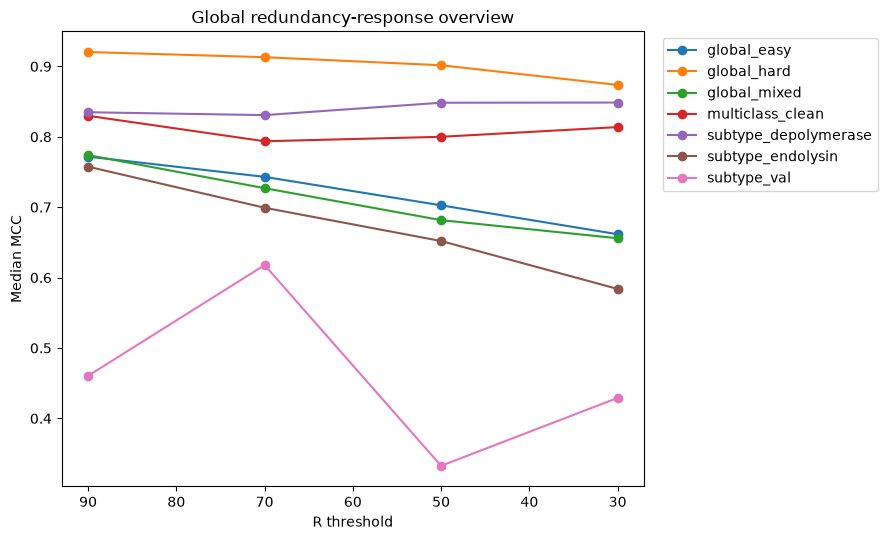

In [4]:
overview = (
    master.groupby(["task", "R"], as_index=False)
    .agg(
        mcc_median=("mcc", "median"),
        mcc_mean=("mcc", "mean"),
        mcc_min=("mcc", "min"),
        mcc_max=("mcc", "max"),
    )
)

display(overview)

fig, ax = plt.subplots(figsize=(9, 5.5))
for task, g in overview.groupby("task"):
    g = g.set_index("R").reindex(R_LEVELS)
    ax.plot(R_LEVELS, g["mcc_median"], marker="o", label=task)

ax.set_xlabel("R threshold")
ax.set_ylabel("Median MCC")
ax.set_title("Global redundancy-response overview")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 3. Complete R curves at fixed S

TASK           = global_easy
REPRESENTATION = esm2_t30_150m
ALGORITHM      = XGB
METRIC         = mcc


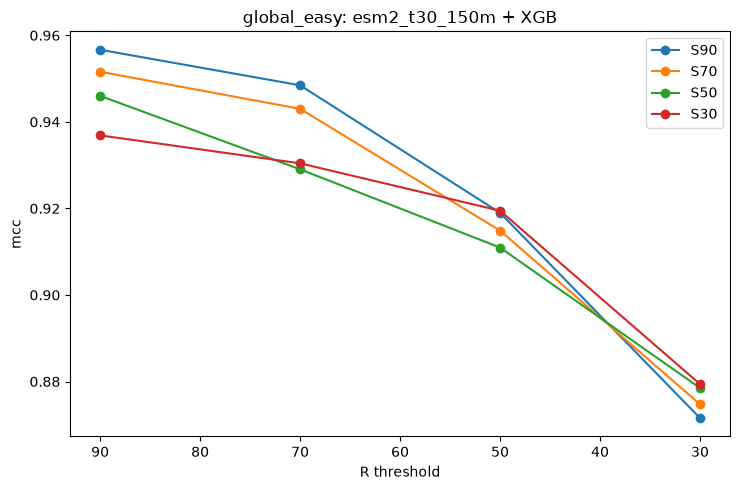

In [5]:
TASK = "global_easy"
REPRESENTATION = (
    "esm2_t30_150m"
    if "esm2_t30_150m" in master["representation"].unique()
    else sorted(master["representation"].unique())[0]
)
ALGORITHM = (
    "XGB"
    if "XGB" in master["algorithm"].unique()
    else sorted(master["algorithm"].unique())[0]
)
METRIC = "mcc"

print("TASK           =", TASK)
print("REPRESENTATION =", REPRESENTATION)
print("ALGORITHM      =", ALGORITHM)
print("METRIC         =", METRIC)

g = master[
    master["task"].eq(TASK)
    & master["representation"].eq(REPRESENTATION)
    & master["algorithm"].eq(ALGORITHM)
].copy()

fig, ax = plt.subplots(figsize=(7.5, 5))
for s in S_LEVELS:
    curve = (
        g[g["S"].eq(s)]
        .set_index("R")
        .reindex(R_LEVELS)
    )
    ax.plot(R_LEVELS, curve[METRIC], marker="o", label=f"S{s}")

ax.set_xlabel("R threshold")
ax.set_ylabel(METRIC)
ax.set_title(f"{TASK}: {REPRESENTATION} + {ALGORITHM}")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 4. All six redundancy contrasts at fixed S

Metrics in Stage12B R-delta table: ['ap', 'ap_gain', 'macro_f1', 'mcc']


,R_from,R_to,n,mean_delta,median_delta,std_delta,q25,q75,min_delta,max_delta,fraction_negative,fraction_positive,contrast
0,50,30,560,-0.013584,-0.022173,0.066795,-0.043332,0.006524,-0.332676,0.418899,0.685714,0.282143,R50→R30
1,70,30,560,-0.054919,-0.046893,0.089721,-0.081794,-0.005116,-0.616528,0.182626,0.769643,0.208929,R70→R30
2,70,50,560,-0.041335,-0.023619,0.094041,-0.049133,0.000000,-0.689417,0.332676,0.725000,0.248214,R70→R50
3,90,30,560,-0.073171,-0.070347,0.106424,-0.119882,-0.018135,-0.513991,0.514487,0.821429,0.164286,R90→R30
4,90,50,560,-0.059587,-0.044738,0.103477,-0.086495,-0.014560,-0.678785,0.567878,0.817857,0.162500,R90→R50
5,90,70,560,-0.018252,-0.022014,0.073930,-0.052118,0.000000,-0.389728,0.482710,0.735714,0.248214,R90→R70


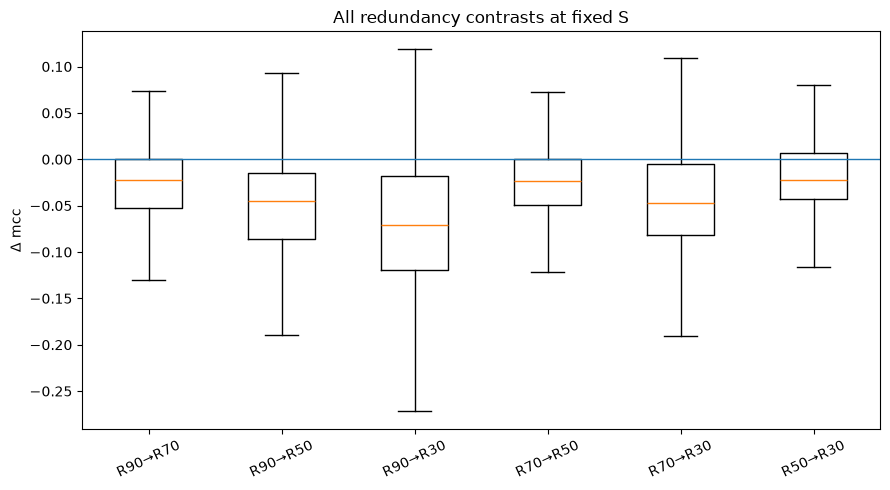

In [6]:
r_metrics = sorted(r_deltas["metric"].dropna().unique())
print("Metrics in Stage12B R-delta table:", r_metrics)

R_METRIC = "mcc" if "mcc" in r_metrics else r_metrics[0]
rd = r_deltas[r_deltas["metric"].eq(R_METRIC)].copy()

ordered_pairs = [
    (90, 70), (90, 50), (90, 30),
    (70, 50), (70, 30),
    (50, 30),
]

contrast_summary = (
    rd.groupby(["R_from", "R_to"], as_index=False)
    .agg(
        n=("delta", "size"),
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        std_delta=("delta", "std"),
        q25=("delta", lambda x: x.quantile(0.25)),
        q75=("delta", lambda x: x.quantile(0.75)),
        min_delta=("delta", "min"),
        max_delta=("delta", "max"),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
        fraction_positive=("delta", lambda x: (x > 0).mean()),
    )
)
contrast_summary["contrast"] = (
    "R" + contrast_summary["R_from"].astype(str)
    + "→R" + contrast_summary["R_to"].astype(str)
)
display(contrast_summary)

fig, ax = plt.subplots(figsize=(9, 5))
data = [
    rd.loc[
        rd["R_from"].eq(a) & rd["R_to"].eq(b),
        "delta"
    ].dropna().to_numpy()
    for a, b in ordered_pairs
]
labels = [f"R{a}→R{b}" for a, b in ordered_pairs]

ax.boxplot(data, tick_labels=labels, showfliers=False)
ax.axhline(0, linewidth=1)
ax.set_ylabel(f"Δ {R_METRIC}")
ax.set_title("All redundancy contrasts at fixed S")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 5. Stepwise effects and dominant transition

In [7]:
step_pairs = [(90, 70), (70, 50), (50, 30)]

step_rd = rd[
    rd.apply(
        lambda x: (int(x["R_from"]), int(x["R_to"])) in step_pairs,
        axis=1,
    )
].copy()

step_rd["abs_delta"] = step_rd["delta"].abs()
step_rd["step"] = (
    "R" + step_rd["R_from"].astype(str)
    + "→R" + step_rd["R_to"].astype(str)
)

step_summary = (
    step_rd.groupby(["R_from", "R_to"], as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
)
step_summary["step"] = (
    "R" + step_summary["R_from"].astype(str)
    + "→R" + step_summary["R_to"].astype(str)
)
display(step_summary)

dominant_step = (
    step_rd.sort_values(
        ["task", "representation", "algorithm", "S_fixed", "abs_delta"],
        ascending=[True, True, True, True, False],
        kind="stable",
    )
    .groupby(
        ["task", "representation", "algorithm", "S_fixed"],
        as_index=False,
    )
    .first()
)

display(
    dominant_step["step"]
    .value_counts(normalize=True)
    .rename("fraction_of_model×S_groups")
    .to_frame()
)

dominant_by_task = (
    dominant_step.groupby(["task", "step"])
    .size()
    .rename("n")
    .reset_index()
)
dominant_by_task["fraction_within_task"] = (
    dominant_by_task["n"]
    / dominant_by_task.groupby("task")["n"].transform("sum")
)
display(
    dominant_by_task.sort_values(
        ["task", "fraction_within_task"],
        ascending=[True, False],
    )
)

,R_from,R_to,mean_delta,median_delta,mean_abs_delta,median_abs_delta,fraction_negative,step
0,50,30,-0.013584,-0.022173,0.044756,0.031941,0.685714,R50→R30
1,70,50,-0.041335,-0.023619,0.055452,0.030822,0.725000,R70→R50
2,90,70,-0.018252,-0.022014,0.049466,0.034586,0.735714,R90→R70


,fraction_of_model×S_groups
step,
R50→R30,0.375000
R90→R70,0.342857
R70→R50,0.282143


,task,step,n,fraction_within_task
0,global_easy,R50→R30,36,0.4500
1,global_easy,R70→R50,25,0.3125
2,global_easy,R90→R70,19,0.2375
3,global_hard,R50→R30,44,0.5500
5,global_hard,R90→R70,21,0.2625
4,global_hard,R70→R50,15,0.1875
8,global_mixed,R90→R70,31,0.3875
6,global_mixed,R50→R30,30,0.3750
7,global_mixed,R70→R50,19,0.2375
11,multiclass_clean,R90→R70,44,0.5500


## 6. Response-shape classification

In [8]:
MONOTONIC_TOL = 0.005

shape_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys
    curve = (
        grp.set_index("R")
        .reindex(R_LEVELS)["mcc"]
        .astype(float)
    )

    if curve.isna().any():
        continue

    values = curve.to_numpy()
    diffs = np.diff(values)  # R90 -> R70 -> R50 -> R30

    if np.all(np.abs(diffs) <= MONOTONIC_TOL):
        shape = "flat"
    elif np.all(diffs <= MONOTONIC_TOL):
        shape = "monotonic_decrease"
    elif np.all(diffs >= -MONOTONIC_TOL):
        shape = "monotonic_increase"
    else:
        shape = "nonmonotonic"

    shape_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "S": s,
            "shape": shape,
            "R90": values[0],
            "R70": values[1],
            "R50": values[2],
            "R30": values[3],
            "delta_R30_minus_R90": values[3] - values[0],
            "max_step_abs": float(np.max(np.abs(diffs))),
        }
    )

shape_df = pd.DataFrame(shape_rows)

display(
    shape_df["shape"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

display(
    pd.crosstab(
        shape_df["task"],
        shape_df["shape"],
        normalize="index",
    )
)

,fraction
shape,
monotonic_decrease,0.503571
nonmonotonic,0.444643
monotonic_increase,0.041071
flat,0.010714


shape,flat,monotonic_decrease,monotonic_increase,nonmonotonic
task,,,,
global_easy,0.000,0.7625,0.0000,0.2375
global_hard,0.000,0.6875,0.0000,0.3125
global_mixed,0.000,0.8500,0.0000,0.1500
multiclass_clean,0.000,0.1000,0.0125,0.8875
subtype_depolymerase,0.000,0.0875,0.2375,0.6750
subtype_endolysin,0.000,0.9250,0.0000,0.0750
subtype_val,0.075,0.1125,0.0375,0.7750


## 7. Performance retention relative to R90

,mean,median,std,min,max
R,,,,,
30,-0.073171,-0.070347,0.106424,-0.513991,0.514487
50,-0.059587,-0.044738,0.103477,-0.678785,0.567878
70,-0.018252,-0.022014,0.073930,-0.389728,0.482710
90,0.000000,0.000000,0.000000,0.000000,0.000000


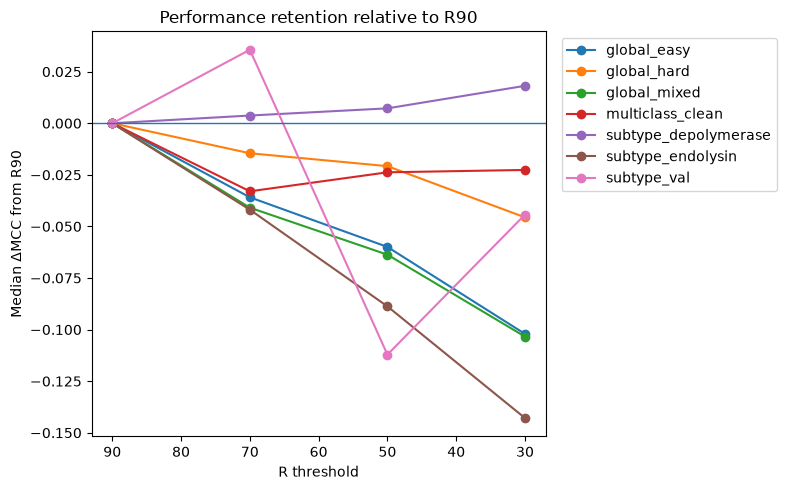

In [9]:
retention_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "S"]
):
    task, rep, alg, s = keys
    lookup = dict(zip(grp["R"].astype(int), grp["mcc"].astype(float)))

    if 90 not in lookup:
        continue

    baseline = lookup[90]

    for r in R_LEVELS:
        if r not in lookup:
            continue

        retention_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "S": s,
                "R": r,
                "mcc": lookup[r],
                "delta_from_R90": lookup[r] - baseline,
                "mcc_ratio_to_R90": (
                    lookup[r] / baseline
                    if baseline != 0
                    else np.nan
                ),
            }
        )

performance_retention = pd.DataFrame(retention_rows)

display(
    performance_retention.groupby("R")["delta_from_R90"]
    .agg(["mean", "median", "std", "min", "max"])
)

fig, ax = plt.subplots(figsize=(8, 5))
for task, g in performance_retention.groupby("task"):
    summary = (
        g.groupby("R")["delta_from_R90"]
        .median()
        .reindex(R_LEVELS)
    )
    ax.plot(R_LEVELS, summary, marker="o", label=task)

ax.axhline(0, linewidth=1)
ax.set_xlabel("R threshold")
ax.set_ylabel("Median ΔMCC from R90")
ax.set_title("Performance retention relative to R90")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 8. Task, representation, and learner redundancy sensitivity

In [10]:
extreme_r = rd[
    rd["R_from"].eq(90)
    & rd["R_to"].eq(30)
].copy()

def sensitivity_table(df, group):
    return (
        df.groupby(group, as_index=False)
        .agg(
            mean_delta=("delta", "mean"),
            median_delta=("delta", "median"),
            mean_abs_delta=("delta", lambda x: x.abs().mean()),
            median_abs_delta=("delta", lambda x: x.abs().median()),
            min_delta=("delta", "min"),
            max_delta=("delta", "max"),
            fraction_negative=("delta", lambda x: (x < 0).mean()),
        )
        .sort_values("median_abs_delta", ascending=False)
    )

task_sensitivity = sensitivity_table(extreme_r, "task")
rep_sensitivity = sensitivity_table(extreme_r, "representation")
alg_sensitivity = sensitivity_table(extreme_r, "algorithm")

print("By task")
display(task_sensitivity)

print("By representation")
display(rep_sensitivity)

print("By algorithm")
display(alg_sensitivity)

By task


,task,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
5,subtype_endolysin,-0.161694,-0.142878,0.161694,0.142878,-0.513991,-0.062069,1.0000
6,subtype_val,-0.067767,-0.044254,0.149505,0.111745,-0.497191,0.514487,0.5875
2,global_mixed,-0.117770,-0.103402,0.117770,0.103402,-0.350685,-0.025496,1.0000
0,global_easy,-0.112667,-0.102103,0.112667,0.102103,-0.372241,-0.020104,1.0000
1,global_hard,-0.053908,-0.045614,0.054183,0.045614,-0.154351,0.011016,0.9875
4,subtype_depolymerase,0.024989,0.018144,0.046881,0.037814,-0.092780,0.182626,0.3750
3,multiclass_clean,-0.023381,-0.022622,0.036300,0.030760,-0.138367,0.136891,0.8000


By representation


,representation,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
2,onehot_1024,-0.121581,-0.095149,0.135181,0.098644,-0.513991,0.182626,0.850000
3,roxy_48,-0.068453,-0.077351,0.096382,0.086618,-0.497191,0.240233,0.785714
1,esm2_t6_8m,-0.051633,-0.056965,0.089260,0.083029,-0.291634,0.514487,0.800000
0,esm2_t30_150m,-0.051018,-0.056807,0.067178,0.062409,-0.278173,0.176985,0.850000


By algorithm


,algorithm,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
3,RF,-0.063485,-0.081927,0.094928,0.091442,-0.435370,0.240233,0.776786
0,KNN,-0.106397,-0.083245,0.126066,0.088282,-0.513991,0.514487,0.892857
4,XGB,-0.076797,-0.076951,0.095445,0.078729,-0.437966,0.243086,0.812500
2,MLP,-0.074506,-0.071688,0.091819,0.076000,-0.339206,0.445389,0.857143
1,LR,-0.044670,-0.051464,0.076742,0.062644,-0.339206,0.376532,0.767857


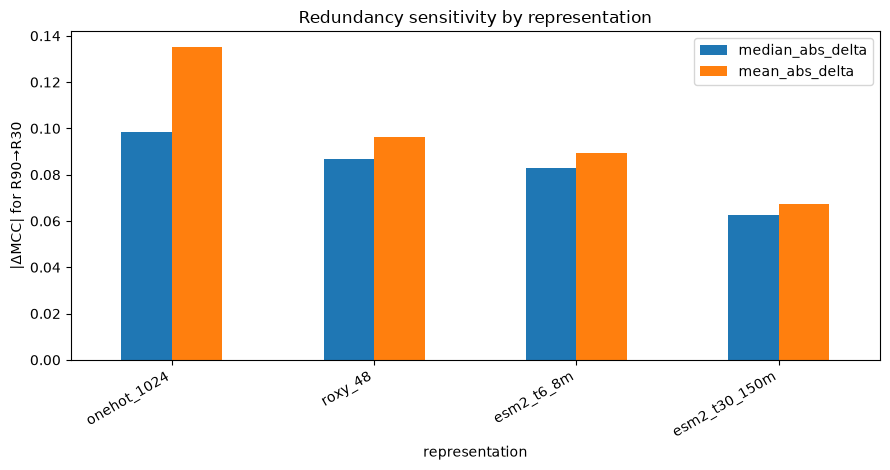

In [11]:
rep_sensitivity.set_index("representation")[
    ["median_abs_delta", "mean_abs_delta"]
].plot(kind="bar", figsize=(9, 4.8))

plt.ylabel("|ΔMCC| for R90→R30")
plt.title("Redundancy sensitivity by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 9. Reconstruct training evidence state for every task × R × S cell

We now reconstruct:

- total eligible entities;
- train/test entities;
- train/test S-level cluster counts;
- mean train entities per S-level cluster;
- positive support when it can be inferred safely.

Again: cluster counts are used as **relative richness statistics**, not as nested cluster survival.

In [12]:
COUNTS_CACHE = CACHE_DIR / "rq2v2_predictive_universe_counts.tsv"
FORCE_RECOUNT = False

def infer_split_column(df):
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(f"No split column found. Columns: {list(df.columns)}")

def infer_cluster_column(df):
    for c in ["cluster_id", "mmseqs_cluster_id", "cluster"]:
        if c in df.columns:
            return c
    return None

def infer_binary_label_column(df):
    candidates = [
        "y", "y_true", "label", "target",
        "binary_label", "class_label",
    ]
    allowed = {
        "0", "1", "0.0", "1.0",
        "positive", "negative", "p", "n",
    }

    for c in candidates:
        if c not in df.columns:
            continue
        vals = set(
            pd.Series(df[c])
            .dropna()
            .astype(str)
            .str.lower()
            .unique()
        )
        if vals and vals <= allowed:
            return c

    return None

def count_predictive_universe():
    rows = []

    for task, task_path in TASK_PATHS.items():
        for r in R_LEVELS:
            for s in S_LEVELS:
                path = (
                    PREDICTIVE_ROOT
                    / task_path
                    / f"R{r}_S{s}"
                    / "eligible_entities.tsv.gz"
                )

                if not path.is_file():
                    rows.append(
                        {
                            "task": task,
                            "R": r,
                            "S": s,
                            "found": False,
                            "path": str(path),
                        }
                    )
                    continue

                df = pd.read_csv(path, sep="\t", low_memory=False)
                split_col = infer_split_column(df)
                cluster_col = infer_cluster_column(df)
                label_col = (
                    infer_binary_label_column(df)
                    if task in BINARY_TASKS
                    else None
                )

                split_norm = df[split_col].astype(str).str.lower()
                train_mask = split_norm.eq("train")
                test_mask = split_norm.eq("test")

                n_train = int(train_mask.sum())
                n_test = int(test_mask.sum())

                if cluster_col:
                    n_clusters_total = int(df[cluster_col].nunique())
                    n_clusters_train = int(df.loc[train_mask, cluster_col].nunique())
                    n_clusters_test = int(df.loc[test_mask, cluster_col].nunique())
                else:
                    n_clusters_total = np.nan
                    n_clusters_train = np.nan
                    n_clusters_test = np.nan

                row = {
                    "task": task,
                    "R": r,
                    "S": s,
                    "found": True,
                    "path": str(path),
                    "n_total": len(df),
                    "n_train": n_train,
                    "n_test": n_test,
                    "n_clusters_total": n_clusters_total,
                    "n_clusters_train": n_clusters_train,
                    "n_clusters_test": n_clusters_test,
                    "train_entities_per_cluster": (
                        n_train / n_clusters_train
                        if pd.notna(n_clusters_train) and n_clusters_train > 0
                        else np.nan
                    ),
                    "test_entities_per_cluster": (
                        n_test / n_clusters_test
                        if pd.notna(n_clusters_test) and n_clusters_test > 0
                        else np.nan
                    ),
                    "cluster_column": cluster_col or "",
                    "label_column": label_col or "",
                }

                if label_col:
                    y = df[label_col].astype(str).str.lower()
                    pos = y.isin({"1", "1.0", "positive", "p"})
                    row["n_positive_total"] = int(pos.sum())
                    row["n_positive_train"] = int((pos & train_mask).sum())
                    row["n_positive_test"] = int((pos & test_mask).sum())

                rows.append(row)

    return pd.DataFrame(rows)

if COUNTS_CACHE.is_file() and not FORCE_RECOUNT:
    counts = pd.read_csv(COUNTS_CACHE, sep="\t", low_memory=False)
    print("Loaded:", COUNTS_CACHE)
else:
    counts = count_predictive_universe()
    counts.to_csv(COUNTS_CACHE, sep="\t", index=False)
    print("Wrote:", COUNTS_CACHE)

print("Cells found:", counts["found"].sum(), "/", len(counts))
display(counts.head())

Wrote: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2v2_predictive_universe_counts.tsv
Cells found: 112 / 112


,task,R,S,found,path,n_total,n_train,n_test,n_clusters_total,n_clusters_train,n_clusters_test,train_entities_per_cluster,test_entities_per_cluster,cluster_column,label_column,n_positive_total,n_positive_train,n_positive_test
0,global_easy,90,90,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21049,9043,30083,21041,9042,1.000380,1.000111,cluster_id,label,4763.0,3324.0,1439.0
1,global_easy,90,70,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21050,9042,21485,15029,6456,1.400625,1.400558,cluster_id,label,4763.0,3321.0,1442.0
2,global_easy,90,50,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21068,9024,14786,10284,4502,2.048619,2.004442,cluster_id,label,4763.0,3380.0,1383.0
3,global_easy,90,30,True,/home/david/Desktop/colabs/inta_project/phagel...,30092,21076,9016,8995,6238,2757,3.378647,3.270221,cluster_id,label,4763.0,3284.0,1479.0
4,global_easy,70,90,True,/home/david/Desktop/colabs/inta_project/phagel...,21512,15058,6454,21507,15055,6452,1.000199,1.000310,cluster_id,label,3463.0,2437.0,1026.0


## 10. Entity retention, relative cluster richness, and redundancy density

For every `task × S`, use `R90` as the descriptive reference state:

\[
E_{\mathrm{ratio}}(R)
=
\frac{N_{\mathrm{train}}(R)}
     {N_{\mathrm{train}}(R90)}
\]

\[
C_{\mathrm{ratio}}(R)
=
\frac{N_{\mathrm{S\text{-}clusters,train}}(R)}
     {N_{\mathrm{S\text{-}clusters,train}}(R90)}
\]

and:

\[
D(R)
=
\frac{N_{\mathrm{train}}(R)}
     {N_{\mathrm{S\text{-}clusters,train}}(R)}
\]

`C_ratio` is **relative richness**, not literal survival of the same clusters.

In [13]:
evidence_state_rows = []

valid_counts = counts[counts["found"]].copy()

for (task, s), grp in valid_counts.groupby(["task", "S"]):
    base = grp[grp["R"].eq(90)]

    if len(base) != 1:
        continue

    base = base.iloc[0]

    for rec in grp.to_dict("records"):
        entity_ratio = (
            rec["n_train"] / base["n_train"]
            if base["n_train"] > 0
            else np.nan
        )

        cluster_ratio = (
            rec["n_clusters_train"] / base["n_clusters_train"]
            if (
                pd.notna(rec["n_clusters_train"])
                and pd.notna(base["n_clusters_train"])
                and base["n_clusters_train"] > 0
            )
            else np.nan
        )

        density_ratio = (
            rec["train_entities_per_cluster"]
            / base["train_entities_per_cluster"]
            if (
                pd.notna(rec["train_entities_per_cluster"])
                and pd.notna(base["train_entities_per_cluster"])
                and base["train_entities_per_cluster"] > 0
            )
            else np.nan
        )

        evidence_state_rows.append(
            {
                "task": task,
                "S": s,
                "R": rec["R"],
                "n_train": rec["n_train"],
                "n_clusters_train": rec["n_clusters_train"],
                "train_entities_per_cluster": rec["train_entities_per_cluster"],
                "entity_retention_ratio": entity_ratio,
                "cluster_richness_ratio": cluster_ratio,
                "density_ratio_to_R90": density_ratio,
                "cluster_minus_entity_retention": (
                    cluster_ratio - entity_ratio
                    if pd.notna(cluster_ratio) and pd.notna(entity_ratio)
                    else np.nan
                ),
            }
        )

evidence_state = pd.DataFrame(evidence_state_rows)

display(
    evidence_state.groupby("R")[
        [
            "entity_retention_ratio",
            "cluster_richness_ratio",
            "density_ratio_to_R90",
            "cluster_minus_entity_retention",
        ]
    ]
    .agg(["mean", "median", "min", "max"])
)

entity_retention_ratio                               cluster_richness_ratio                               density_ratio_to_R90                               cluster_minus_entity_retention                      \
                     mean    median       min       max                   mean    median       min       max                 mean    median       min       max                           mean    median       min   
R                                                                                                                                                                                                                    
30               0.320252  0.307481  0.298114  0.373060               0.600654  0.559600  0.298227  1.007043             0.635972  0.623930  0.296495  1.001170                       0.280402  0.221500 -0.000435   
50               0.503589  0.497003  0.490902  0.530172               0.802467  0.856301  0.490946  1.011744             0.681227  0.623784  0.487438  1.001536                       0.298878  0.329775 -0.000811   
70               0.722520  0.717154  0.713776  0.745123               0.932131  1.000193  0.715374  1.009483             0.790844  0.720721  0.708295  1.000387                       0.209611  0.278047 -0.000285   
90               1.000000  1.000000  1.000000  1.000000               1.000000  1.000000  1.000000  1.000000             1.000000  1.000000  1.000000  1.000000                       0.000000  0.000000  0.000000   

              
         max  
R             
30  0.708129  
50  0.516342  
70  0.294471  
90  0.000000

### Interpretation

If `cluster_richness_ratio > entity_retention_ratio`, then entity count is collapsing faster than the number of S-level sequence clusters represented in training.

That pattern is compatible with preferential removal of **within-cluster repetition** before comparable loss of cluster-level richness.

,entity_retention_median,cluster_richness_median,density_ratio_median
R,,,
90,1.000000,1.000000,1.000000
70,0.717154,1.000193,0.720721
50,0.497003,0.856301,0.623784
30,0.307481,0.559600,0.623930


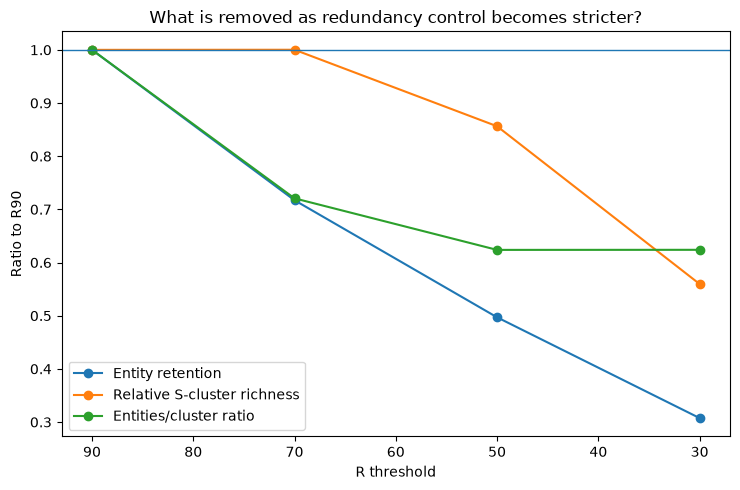

In [14]:
retention_summary = (
    evidence_state.groupby("R", as_index=False)
    .agg(
        entity_retention_median=("entity_retention_ratio", "median"),
        cluster_richness_median=("cluster_richness_ratio", "median"),
        density_ratio_median=("density_ratio_to_R90", "median"),
    )
    .set_index("R")
    .reindex(R_LEVELS)
)

display(retention_summary)

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(
    R_LEVELS,
    retention_summary["entity_retention_median"],
    marker="o",
    label="Entity retention",
)
ax.plot(
    R_LEVELS,
    retention_summary["cluster_richness_median"],
    marker="o",
    label="Relative S-cluster richness",
)
ax.plot(
    R_LEVELS,
    retention_summary["density_ratio_median"],
    marker="o",
    label="Entities/cluster ratio",
)

ax.axhline(1, linewidth=1)
ax.set_xlabel("R threshold")
ax.set_ylabel("Ratio to R90")
ax.set_title("What is removed as redundancy control becomes stricter?")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 11. Evidence-state trajectories by task

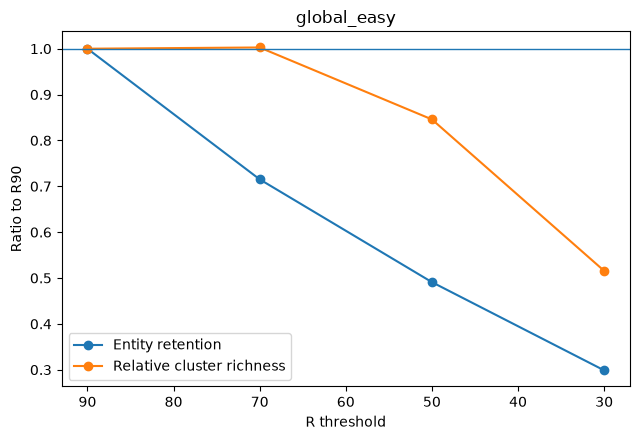

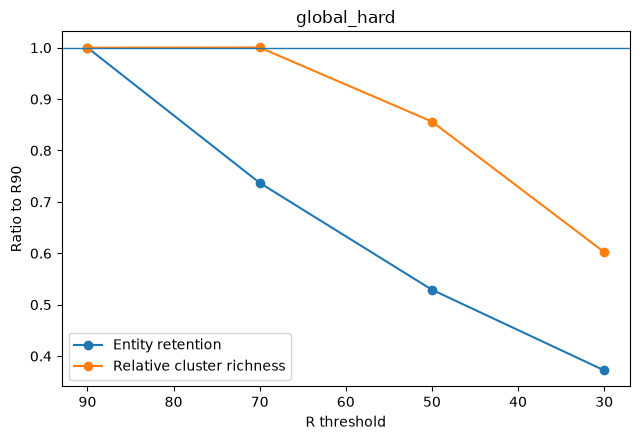

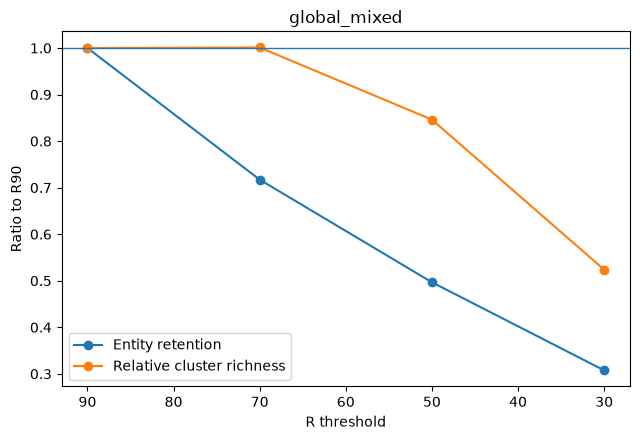

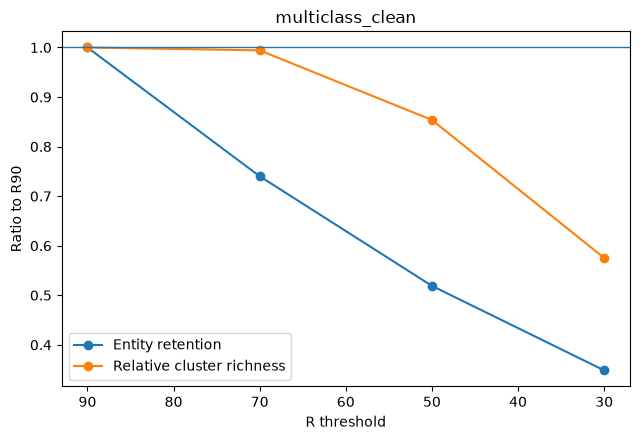

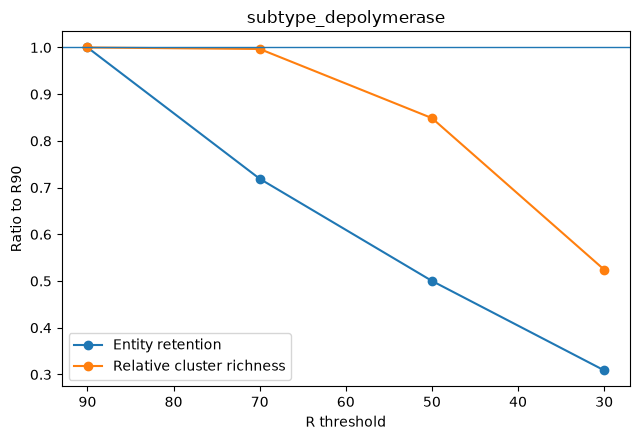

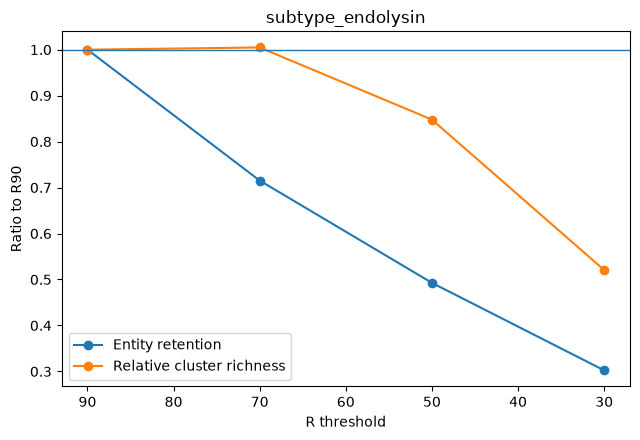

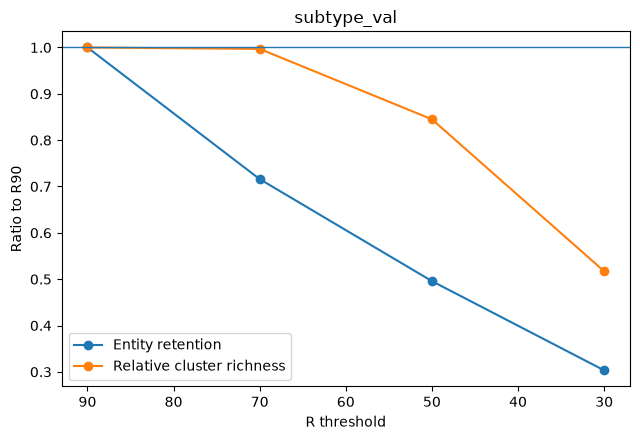

In [15]:
for task, g in evidence_state.groupby("task"):
    med = (
        g.groupby("R")[
            [
                "entity_retention_ratio",
                "cluster_richness_ratio",
            ]
        ]
        .median()
        .reindex(R_LEVELS)
    )

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(
        R_LEVELS,
        med["entity_retention_ratio"],
        marker="o",
        label="Entity retention",
    )
    ax.plot(
        R_LEVELS,
        med["cluster_richness_ratio"],
        marker="o",
        label="Relative cluster richness",
    )
    ax.axhline(1, linewidth=1)
    ax.set_xlabel("R threshold")
    ax.set_ylabel("Ratio to R90")
    ax.set_title(task)
    ax.legend()
    ax.invert_xaxis()
    plt.tight_layout()
    plt.show()

## 12. Join predictive retention with evidence retention

Performance varies by representation/algorithm, while evidence-state ratios depend only on `task × R × S`.

This lets us ask:

> For the **same biological evidence reduction**, which model families lose more predictive performance?

In [16]:
perf_evidence = performance_retention.merge(
    evidence_state,
    on=["task", "R", "S"],
    how="left",
    validate="many_to_one",
)

display(
    perf_evidence[
        [
            "task", "representation", "algorithm", "R", "S",
            "delta_from_R90",
            "entity_retention_ratio",
            "cluster_richness_ratio",
            "density_ratio_to_R90",
        ]
    ].head()
)

,task,representation,algorithm,R,S,delta_from_R90,entity_retention_ratio,cluster_richness_ratio,density_ratio_to_R90
0,global_easy,esm2_t30_150m,KNN,90,30,0.000000,1.000000,1.000000,1.000000
1,global_easy,esm2_t30_150m,KNN,70,30,-0.008368,0.715743,1.009138,0.709262
2,global_easy,esm2_t30_150m,KNN,50,30,-0.029956,0.491032,1.007374,0.487438
3,global_easy,esm2_t30_150m,KNN,30,30,-0.060375,0.298444,1.006573,0.296495
4,global_easy,esm2_t30_150m,KNN,90,50,0.000000,1.000000,1.000000,1.000000


## 13. R90→R30: performance retained versus evidence retained

In [17]:
extreme_state = perf_evidence[
    perf_evidence["R"].eq(30)
].copy()

extreme_overview = (
    extreme_state.groupby("task", as_index=False)
    .agg(
        median_delta_mcc=("delta_from_R90", "median"),
        median_mcc_ratio=("mcc_ratio_to_R90", "median"),
        entity_retention_ratio=("entity_retention_ratio", "median"),
        cluster_richness_ratio=("cluster_richness_ratio", "median"),
        density_ratio=("density_ratio_to_R90", "median"),
    )
)

display(extreme_overview)

,task,median_delta_mcc,median_mcc_ratio,entity_retention_ratio,cluster_richness_ratio,density_ratio
0,global_easy,-0.102103,0.870035,0.298667,0.515604,0.601223
1,global_hard,-0.045614,0.951214,0.372273,0.602355,0.634432
2,global_mixed,-0.103402,0.865425,0.307481,0.523817,0.607005
3,multiclass_clean,-0.022622,0.969361,0.348435,0.575271,0.627342
4,subtype_depolymerase,0.018144,1.021900,0.308831,0.524458,0.608603
5,subtype_endolysin,-0.142878,0.798092,0.302377,0.520580,0.602110
6,subtype_val,-0.044254,0.882616,0.303231,0.517084,0.607136


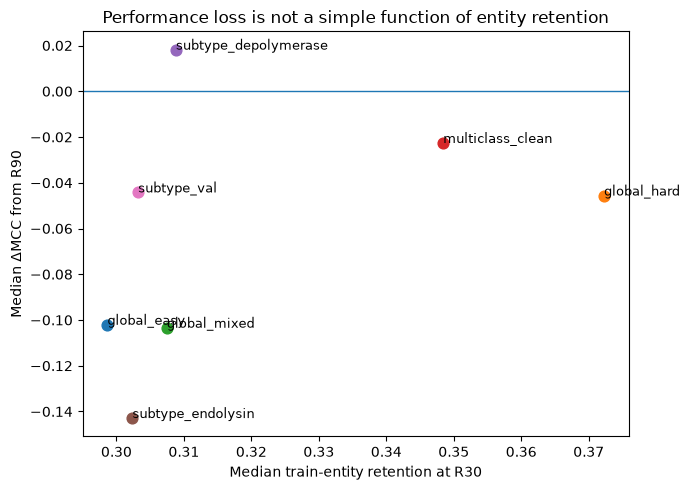

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))

for task, g in extreme_state.groupby("task"):
    x = g["entity_retention_ratio"].median()
    y = g["delta_from_R90"].median()
    ax.scatter(x, y, s=60)
    ax.text(x, y, task, fontsize=9)

ax.axhline(0, linewidth=1)
ax.set_xlabel("Median train-entity retention at R30")
ax.set_ylabel("Median ΔMCC from R90")
ax.set_title("Performance loss is not a simple function of entity retention")
plt.tight_layout()
plt.show()

## 14. Performance loss per 10% of train entities removed

This normalization is valid because entity counts are directly comparable across independently generated R universes.

It does **not** assume nested clusters.

In [19]:
# Build all six entity-removal contrasts at fixed task × S.
entity_contrast_rows = []

for (task, s), grp in evidence_state.groupby(["task", "S"]):
    lookup = grp.set_index("R").to_dict("index")

    for r_from, r_to in [
        (90, 70), (90, 50), (90, 30),
        (70, 50), (70, 30),
        (50, 30),
    ]:
        if r_from not in lookup or r_to not in lookup:
            continue

        n_from = lookup[r_from]["n_train"]
        n_to = lookup[r_to]["n_train"]

        entity_contrast_rows.append(
            {
                "task": task,
                "S_fixed": s,
                "R_from": r_from,
                "R_to": r_to,
                "fraction_train_removed": (
                    (n_from - n_to) / n_from
                    if n_from > 0
                    else np.nan
                ),
            }
        )

entity_contrasts = pd.DataFrame(entity_contrast_rows)

rd_entity = rd.merge(
    entity_contrasts,
    on=["task", "S_fixed", "R_from", "R_to"],
    how="left",
    validate="many_to_one",
)

rd_entity["mcc_loss"] = -rd_entity["delta"]
rd_entity["mcc_loss_per_10pct_train_removed"] = np.where(
    rd_entity["fraction_train_removed"] > 0,
    rd_entity["mcc_loss"]
    / rd_entity["fraction_train_removed"]
    * 0.10,
    np.nan,
)

display(
    rd_entity.groupby(["R_from", "R_to"])[
        [
            "delta",
            "fraction_train_removed",
            "mcc_loss_per_10pct_train_removed",
        ]
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

delta                                         fraction_train_removed                                         mcc_loss_per_10pct_train_removed                                        
                 mean    median       std       min       max                   mean    median       std       min       max                             mean    median       std       min       max
R_from R_to                                                                                                                                                                                          
50     30   -0.013584 -0.022173  0.066795 -0.332676  0.418899               0.364982  0.382495  0.034435  0.295649  0.392722                         0.003804  0.006238  0.017518 -0.108053  0.085637
70     30   -0.054919 -0.046893  0.089721 -0.616528  0.182626               0.557142  0.571339  0.030528  0.494891  0.583278                         0.009658  0.008767  0.015646 -0.032070  0.106992
       50   -0.041335 -0.023619  0.094041 -0.689417  0.332676               0.303121  0.306481  0.010245  0.281460  0.313954                         0.013402  0.007578  0.030575 -0.108230  0.223493
90     30   -0.073171 -0.070347  0.106424 -0.513991  0.514487               0.679748  0.692519  0.026441  0.626940  0.701886                         0.010650  0.010402  0.015288 -0.073844  0.073682
       50   -0.059587 -0.044738  0.103477 -0.678785  0.567878               0.496411  0.502997  0.013676  0.469828  0.509098                         0.011868  0.008946  0.020518 -0.112949  0.134470
       70   -0.018252 -0.022014  0.073930 -0.389728  0.482710               0.277480  0.282846  0.010080  0.254877  0.286224                         0.006593  0.008020  0.026164 -0.169334  0.137083

## 15. Representation robustness after normalizing for entity removal

,representation,median_mcc_loss,median_loss_per_10pct_removed,mean_loss_per_10pct_removed,q25_loss_per_10pct_removed,q75_loss_per_10pct_removed
2,onehot_1024,0.030999,0.010114,0.013404,-0.000000,0.024967
3,roxy_48,0.025435,0.007834,0.007495,-0.002855,0.016441
1,esm2_t6_8m,0.022348,0.007205,0.005573,-0.001096,0.013687
0,esm2_t30_150m,0.017551,0.005997,0.005260,0.000884,0.010279


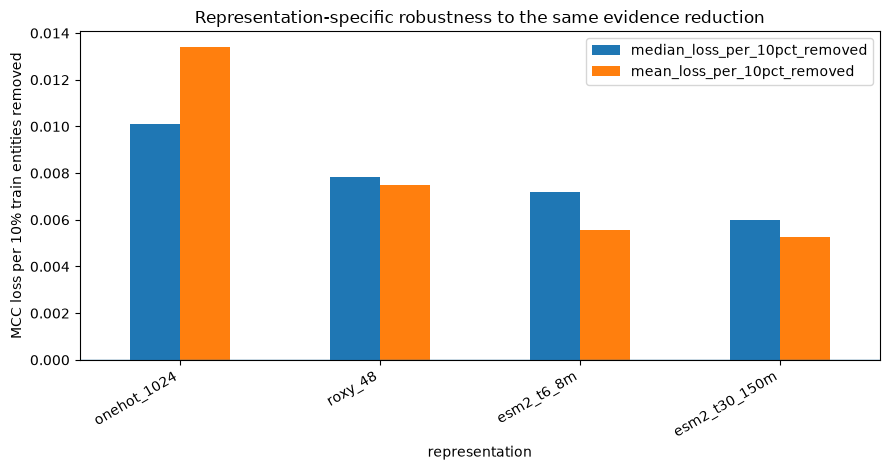

In [20]:
step_entity = rd_entity[
    rd_entity.apply(
        lambda x: (int(x["R_from"]), int(x["R_to"])) in step_pairs,
        axis=1,
    )
].copy()

normalized_rep = (
    step_entity.groupby("representation", as_index=False)
    .agg(
        median_mcc_loss=("mcc_loss", "median"),
        median_loss_per_10pct_removed=(
            "mcc_loss_per_10pct_train_removed",
            "median",
        ),
        mean_loss_per_10pct_removed=(
            "mcc_loss_per_10pct_train_removed",
            "mean",
        ),
        q25_loss_per_10pct_removed=(
            "mcc_loss_per_10pct_train_removed",
            lambda x: x.quantile(0.25),
        ),
        q75_loss_per_10pct_removed=(
            "mcc_loss_per_10pct_train_removed",
            lambda x: x.quantile(0.75),
        ),
    )
    .sort_values("median_loss_per_10pct_removed", ascending=False)
)

display(normalized_rep)

normalized_rep.set_index("representation")[
    ["median_loss_per_10pct_removed", "mean_loss_per_10pct_removed"]
].plot(kind="bar", figsize=(9, 4.8))

plt.axhline(0, linewidth=1)
plt.ylabel("MCC loss per 10% train entities removed")
plt.title("Representation-specific robustness to the same evidence reduction")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 16. Does entity quantity alone explain performance loss?

For each `task × representation × algorithm`, examine whether local stepwise MCC loss tracks the fraction of train entities removed.

This is descriptive; each group contains few points and R changes more than sample size.

In [21]:
corr_rows = []

for keys, grp in step_entity.groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys
    x = grp[
        ["fraction_train_removed", "mcc_loss"]
    ].dropna()

    if len(x) < 4 or x["fraction_train_removed"].nunique() < 2:
        rho = np.nan
    else:
        rho = x["fraction_train_removed"].corr(
            x["mcc_loss"],
            method="spearman",
        )

    corr_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "n": len(x),
            "spearman_rho": rho,
        }
    )

quantity_correlations = pd.DataFrame(corr_rows)

display(
    quantity_correlations["spearman_rho"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame("value")
)

,value
count,140.000000
mean,0.012220
median,0.010490
std,0.447305
min,-0.874126
max,0.972028


## 17. Does preservation of relative cluster richness correspond to better performance retention?

This analysis uses **state ratios relative to R90**, not literal cluster-removal counts.

Because cluster richness is recomputed independently in each R universe, interpret associations descriptively.

In [22]:
state_corr_rows = []

for keys, grp in perf_evidence[perf_evidence["R"].ne(90)].groupby(
    ["task", "representation", "algorithm"]
):
    task, rep, alg = keys

    for predictor in [
        "entity_retention_ratio",
        "cluster_richness_ratio",
        "density_ratio_to_R90",
    ]:
        x = grp[[predictor, "delta_from_R90"]].dropna()

        if len(x) < 4 or x[predictor].nunique() < 2:
            rho = np.nan
        else:
            rho = x[predictor].corr(
                x["delta_from_R90"],
                method="spearman",
            )

        state_corr_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "predictor": predictor,
                "n": len(x),
                "spearman_rho": rho,
            }
        )

state_correlations = pd.DataFrame(state_corr_rows)

display(
    state_correlations.groupby("predictor")["spearman_rho"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

,count,mean,median,std,min,max
predictor,,,,,,
cluster_richness_ratio,140,0.505170,0.590909,0.318846,-0.636364,0.923077
density_ratio_to_R90,140,-0.199190,-0.216783,0.325961,-0.846154,0.699301
entity_retention_ratio,140,0.360693,0.465035,0.448254,-0.790478,0.944056


## 18. How much cluster richness is preserved beyond entity retention?

Define the descriptive **richness surplus**:

\[
G(R)=C_{\mathrm{ratio}}(R)-E_{\mathrm{ratio}}(R)
\]

Positive values mean that the relative number of represented S-level clusters remains higher than the relative number of training entities.

This is the clean replacement for the invalid “fraction of clusters removed” interpretation from v1.

,mean,median,std,min,max
R,,,,,
30,0.280402,0.221500,0.263348,-0.000435,0.708129
50,0.298878,0.329775,0.217508,-0.000811,0.516342
70,0.209611,0.278047,0.123698,-0.000285,0.294471
90,0.000000,0.000000,0.000000,0.000000,0.000000


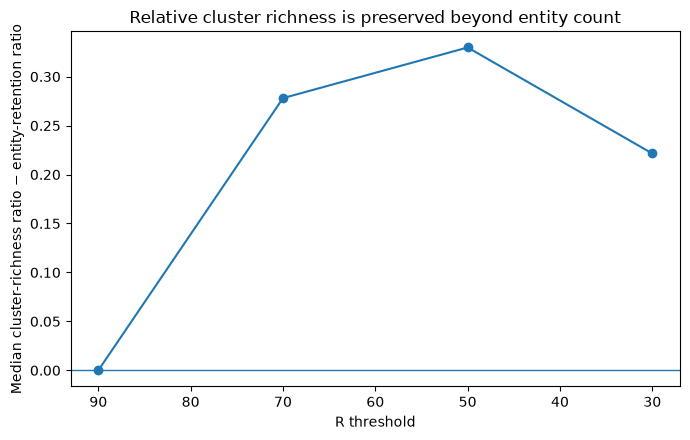

In [23]:
richness_surplus = (
    evidence_state.groupby("R")[
        "cluster_minus_entity_retention"
    ]
    .agg(["mean", "median", "std", "min", "max"])
)

display(richness_surplus)

fig, ax = plt.subplots(figsize=(7, 4.5))
summary = (
    evidence_state.groupby("R")[
        "cluster_minus_entity_retention"
    ]
    .median()
    .reindex(R_LEVELS)
)
ax.plot(R_LEVELS, summary, marker="o")
ax.axhline(0, linewidth=1)
ax.set_xlabel("R threshold")
ax.set_ylabel("Median cluster-richness ratio − entity-retention ratio")
ax.set_title("Relative cluster richness is preserved beyond entity count")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 19. Which tasks preserve cluster richness while losing entities?

In [24]:
task_richness = (
    evidence_state[evidence_state["R"].eq(30)]
    .groupby("task", as_index=False)
    .agg(
        entity_retention=("entity_retention_ratio", "median"),
        cluster_richness=("cluster_richness_ratio", "median"),
        richness_surplus=("cluster_minus_entity_retention", "median"),
        density_ratio=("density_ratio_to_R90", "median"),
    )
    .sort_values("richness_surplus", ascending=False)
)

display(task_richness)

,task,entity_retention,cluster_richness,richness_surplus,density_ratio
1,global_hard,0.372273,0.602355,0.229748,0.634432
3,multiclass_clean,0.348435,0.575271,0.225077,0.627342
5,subtype_endolysin,0.302377,0.520580,0.218126,0.602110
0,global_easy,0.298667,0.515604,0.216492,0.601223
2,global_mixed,0.307481,0.523817,0.216276,0.607005
4,subtype_depolymerase,0.308831,0.524458,0.215672,0.608603
6,subtype_val,0.303231,0.517084,0.213698,0.607136


## 20. Conditioning of the R90→R30 effect by S

In [25]:
extreme_by_s = (
    extreme_r.groupby("S_fixed", as_index=False)
    .agg(
        mean_delta=("delta", "mean"),
        median_delta=("delta", "median"),
        mean_abs_delta=("delta", lambda x: x.abs().mean()),
        median_abs_delta=("delta", lambda x: x.abs().median()),
        fraction_negative=("delta", lambda x: (x < 0).mean()),
    )
)

display(extreme_by_s)

,S_fixed,mean_delta,median_delta,mean_abs_delta,median_abs_delta,fraction_negative
0,30,-0.020187,-0.039645,0.080132,0.064053,0.664286
1,50,-0.067048,-0.069663,0.085161,0.081692,0.828571
2,70,-0.089129,-0.091481,0.099788,0.093130,0.864286
3,90,-0.116321,-0.084248,0.122919,0.087235,0.928571


This is **not** the formal R×S interaction test. It only asks whether the observed R effect changes depending on the S regime. Any strong conditioning signal should be carried forward to the dedicated interaction RQ.

## 21. Binary AP-skill redundancy sensitivity

In [26]:
if "ap_skill" in master.columns:
    binary = master[master["task"].isin(BINARY_TASKS)].copy()
    ap_rows = []

    for keys, grp in binary.groupby(
        ["task", "representation", "algorithm", "S"]
    ):
        task, rep, alg, s = keys
        lookup = dict(
            zip(
                grp["R"].astype(int),
                grp["ap_skill"].astype(float),
            )
        )

        for r_from, r_to in [
            (90, 70), (90, 50), (90, 30),
            (70, 50), (70, 30),
            (50, 30),
        ]:
            if r_from in lookup and r_to in lookup:
                ap_rows.append(
                    {
                        "task": task,
                        "representation": rep,
                        "algorithm": alg,
                        "S_fixed": s,
                        "R_from": r_from,
                        "R_to": r_to,
                        "delta_ap_skill": (
                            lookup[r_to] - lookup[r_from]
                        ),
                    }
                )

    ap_r_deltas = pd.DataFrame(ap_rows)

    display(
        ap_r_deltas[
            ap_r_deltas["R_from"].eq(90)
            & ap_r_deltas["R_to"].eq(30)
        ]
        .groupby("task")["delta_ap_skill"]
        .agg(["mean", "median", "std", "min", "max"])
    )

,mean,median,std,min,max
task,,,,,
global_easy,-0.108460,-0.086692,0.081623,-0.403273,0.035252
global_hard,-0.022082,-0.015133,0.018490,-0.081596,0.011434
global_mixed,-0.118878,-0.099763,0.081686,-0.397119,0.045315
subtype_depolymerase,0.038470,0.029372,0.058074,-0.101076,0.204594
subtype_endolysin,-0.169090,-0.149750,0.103041,-0.565342,-0.048932
subtype_val,-0.040042,-0.045140,0.193360,-0.465259,0.552124


## 22. VAL support-aware diagnostic

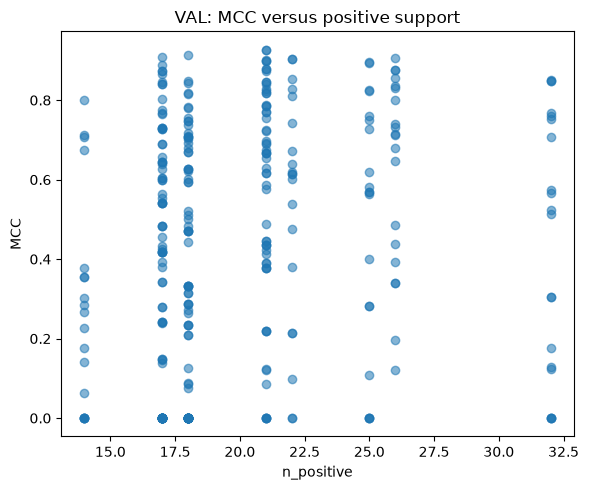

Spearman support vs MCC: 0.22592094554894349


In [27]:
val_master = master[
    master["task"].eq("subtype_val")
].copy()

val_counts = evidence_state[
    evidence_state["task"].eq("subtype_val")
][
    [
        "R", "S",
        "n_train",
        "n_clusters_train",
        "entity_retention_ratio",
        "cluster_richness_ratio",
    ]
].copy()

val_joined = val_master.merge(
    val_counts,
    on=["R", "S"],
    how="left",
    validate="many_to_one",
)

support_candidates = [
    "n_positive",
    "support_positive",
    "n_positive_test",
]

support_col = next(
    (c for c in support_candidates if c in val_joined.columns),
    None,
)

if support_col:
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(
        val_joined[support_col],
        val_joined["mcc"],
        alpha=0.55,
    )
    ax.set_xlabel(support_col)
    ax.set_ylabel("MCC")
    ax.set_title("VAL: MCC versus positive support")
    plt.tight_layout()
    plt.show()

    x = val_joined[[support_col, "mcc"]].dropna()
    if len(x) > 2:
        print(
            "Spearman support vs MCC:",
            x.corr(method="spearman").iloc[0, 1],
        )
else:
    print(
        "No positive-support column found in the aggregated supervised table. "
        "Treat VAL as support-limited and defer detailed support analysis to the dedicated VAL RQ."
    )

# 23. RQ2 v2 synthesis

After execution, RQ2 should answer:

1. What is the median `R90→R30` performance loss?
2. Is degradation globally monotonic?
3. Is there a universal redundancy breakpoint?
4. Which tasks define distinct redundancy-response regimes?
5. Which representations are most robust?
6. Does representation robustness persist after normalization by entity removal?
7. How much training-entity count remains at each R?
8. How much **relative S-level cluster richness** remains at each R?
9. Does cluster richness decline more slowly than entity count?
10. Does training density (`entities/cluster`) collapse as redundancy is removed?
11. Is performance loss proportional to entity loss?
12. Does the magnitude of the R effect depend on S?
13. Which claims should be carried into the generalization-regime synthesis?

In [28]:
rq2_rows = []

# Overall extreme effect.
x = extreme_r["delta"].dropna()
rq2_rows.append(
    {
        "evidence": "overall_R90_to_R30",
        "group": "all",
        "median_delta_mcc": x.median(),
        "mean_delta_mcc": x.mean(),
        "median_abs_delta_mcc": x.abs().median(),
        "fraction_negative": (x < 0).mean(),
        "n": len(x),
    }
)

# Task sensitivity.
for rec in task_sensitivity.to_dict("records"):
    rq2_rows.append(
        {
            "evidence": "R90_to_R30_by_task",
            "group": rec["task"],
            "median_delta_mcc": rec["median_delta"],
            "mean_delta_mcc": rec["mean_delta"],
            "median_abs_delta_mcc": rec["median_abs_delta"],
            "fraction_negative": rec["fraction_negative"],
        }
    )

# Representation sensitivity.
for rec in rep_sensitivity.to_dict("records"):
    rq2_rows.append(
        {
            "evidence": "R90_to_R30_by_representation",
            "group": rec["representation"],
            "median_delta_mcc": rec["median_delta"],
            "mean_delta_mcc": rec["mean_delta"],
            "median_abs_delta_mcc": rec["median_abs_delta"],
            "fraction_negative": rec["fraction_negative"],
        }
    )

# Response shape.
for shape, fraction in shape_df["shape"].value_counts(normalize=True).items():
    rq2_rows.append(
        {
            "evidence": "response_shape",
            "group": shape,
            "fraction": fraction,
        }
    )

# Evidence retention at R30.
r30_state = evidence_state[evidence_state["R"].eq(30)]
rq2_rows.append(
    {
        "evidence": "R30_evidence_state",
        "group": "all_tasks_S",
        "median_entity_retention": r30_state["entity_retention_ratio"].median(),
        "median_cluster_richness_ratio": r30_state["cluster_richness_ratio"].median(),
        "median_density_ratio": r30_state["density_ratio_to_R90"].median(),
        "median_richness_surplus": r30_state["cluster_minus_entity_retention"].median(),
    }
)

rq2_summary = pd.DataFrame(rq2_rows)
display(rq2_summary)

SUMMARY_PATH = CACHE_DIR / "rq2v2_evidence_summary.tsv"
STATE_PATH = CACHE_DIR / "rq2v2_evidence_state.tsv"
PERF_STATE_PATH = CACHE_DIR / "rq2v2_performance_evidence_state.tsv"
SHAPE_PATH = CACHE_DIR / "rq2v2_response_shapes.tsv"
NORMALIZED_REP_PATH = CACHE_DIR / "rq2v2_representation_entity_normalized_loss.tsv"

rq2_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
evidence_state.to_csv(STATE_PATH, sep="\t", index=False)
perf_evidence.to_csv(PERF_STATE_PATH, sep="\t", index=False)
shape_df.to_csv(SHAPE_PATH, sep="\t", index=False)
normalized_rep.to_csv(NORMALIZED_REP_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    STATE_PATH,
    PERF_STATE_PATH,
    SHAPE_PATH,
    NORMALIZED_REP_PATH,
]:
    print(" ", p)

,evidence,group,median_delta_mcc,mean_delta_mcc,median_abs_delta_mcc,fraction_negative,n,fraction,median_entity_retention,median_cluster_richness_ratio,median_density_ratio,median_richness_surplus
0,overall_R90_to_R30,all,-0.070347,-0.073171,0.080191,0.821429,560.0,NaN,NaN,NaN,NaN,NaN
1,R90_to_R30_by_task,subtype_endolysin,-0.142878,-0.161694,0.142878,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
2,R90_to_R30_by_task,subtype_val,-0.044254,-0.067767,0.111745,0.587500,NaN,NaN,NaN,NaN,NaN,NaN
3,R90_to_R30_by_task,global_mixed,-0.103402,-0.117770,0.103402,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
4,R90_to_R30_by_task,global_easy,-0.102103,-0.112667,0.102103,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
5,R90_to_R30_by_task,global_hard,-0.045614,-0.053908,0.045614,0.987500,NaN,NaN,NaN,NaN,NaN,NaN
6,R90_to_R30_by_task,subtype_depolymerase,0.018144,0.024989,0.037814,0.375000,NaN,NaN,NaN,NaN,NaN,NaN
7,R90_to_R30_by_task,multiclass_clean,-0.022622,-0.023381,0.030760,0.800000,NaN,NaN,NaN,NaN,NaN,NaN
8,R90_to_R30_by_representation,onehot_1024,-0.095149,-0.121581,0.098644,0.850000,NaN,NaN,NaN,NaN,NaN,NaN
9,R90_to_R30_by_representation,roxy_48,-0.077351,-0.068453,0.086618,0.785714,NaN,NaN,NaN,NaN,NaN,NaN


Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2v2_evidence_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2v2_evidence_state.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2v2_performance_evidence_state.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2v2_response_shapes.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq2v2_representation_entity_normalized_loss.tsv


## What this notebook should not conclude

Do not state that a lower R simply creates a “harder test split”. It changes the available evidence before splitting.

Do not interpret changes in S-level cluster counts as literal loss or survival of the same clusters across R. The R universes are generated independently and reclustered.

The defensible statements are instead about:

- **entity retention**;
- **relative cluster richness**;
- **training density**;
- **predictive retention**;
- and how these quantities co-vary across redundancy regimes.

Likewise, any strong dependence of the R effect on S should be treated here as evidence motivating the dedicated `R×S` interaction analysis, not as the final interaction result.